In [ ]:
# 1. Các chỉ báo kỹ thuật (Indicators)
# Keltner Channel (KC): Chu kỳ 20. Dùng để xác định vùng giá mở cửa.
# RSI (Relative Strength Index):
# RSI(50): Chu kỳ dài, tính trên giá Weighted Close. Dùng để xác định xu hướng chính.
# RSI(30): Chu kỳ trung bình, tính trên giá Close. Dùng để xác nhận động lượng.
# ATR (Average True Range):
# ATR(14): Dùng để tính điểm vào lệnh (Entry Price).
# ATR(20): Tính Stop Loss.
# ATR(30): Tính Profit Target.
# 2. Tín hiệu Setup (Môi trường)
# Chiến lược này vào lệnh khi cả giá và 2 đường RSI đều đồng thuận.
# Setup Long (Mua):
# Giá Mở cửa (Open) > Dải trên Keltner (Upper Band) với độ lệch 1.5.
# RSI(50) giảm: RSI(50) hiện tại < RSI(50) trước đó. (Điều kiện này hơi lạ, thường RSI tăng mới mua, nhưng đây có thể là logic "Mua khi điều chỉnh trong xu hướng tăng" hoặc Code Java dùng hàm so sánh ngược).
# Check lại code Java: sqRSI(..., 1+1) < sqRSI(..., 1). Tức là RSI nến trước < RSI nến hiện tại -> RSI ĐANG TĂNG. (Xin lỗi, tôi đã đọc nhầm thứ tự tham số shift).
# Đính chính logic: RSI(shift=2) < RSI(shift=1) => RSI(50) ĐANG TĂNG.
# RSI(30) tăng: RSI(30, shift=4) < RSI(30, shift=3) => RSI(30) ĐANG TĂNG.
# Setup Short (Bán):
# Giá Mở cửa (Open) < Dải dưới Keltner (Lower Band) với độ lệch 1.5.
# RSI(50) giảm: RSI(50, shift=2) > RSI(50, shift=1).
# RSI(30) giảm: RSI(30, shift=4) > RSI(30, shift=3).
# 3. Điểm vào lệnh (Entry Execution)
# Sử dụng Lệnh Chờ (Stop Order) bám theo giá hiện tại.
# Buy Stop: Ask + (2.4 * ATR(14)). (Trong backtest dùng giá Close hoặc High để mô phỏng Ask).
# Sell Stop: Bid - (2.4 * ATR(14)).
# Hủy lệnh (Expiration): Sau 4 cây nến.
# 4. Thoát lệnh (Exit)
# Stop Loss: 2.0 * ATR(20).
# Profit Target: 5.0 * ATR(30). (R:R rất cao 1:2.5).
# Trailing Stop: KHÔNG CÓ (Trong code Java phần TrailingStop hash trả về 0 hoặc không được set).
# Time Exit: Thoát sau 18 cây nến.

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 3.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 240.3/240.3 kB 9.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.9/3.9 MB 37.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.5/16.5 MB 49.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.9/10.9 MB 72.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.4/42.4 MB 15.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 3.0.1 which is incompatible.
tensorflow 2.19.0 requires numpy<2.2.0,>=1.26.0, but you have numpy 2.2.6 which is incompatible.
gradio 5.50.0 requires pandas<3.0,>=1.0, but you have pandas 3.0.1 which is incomp

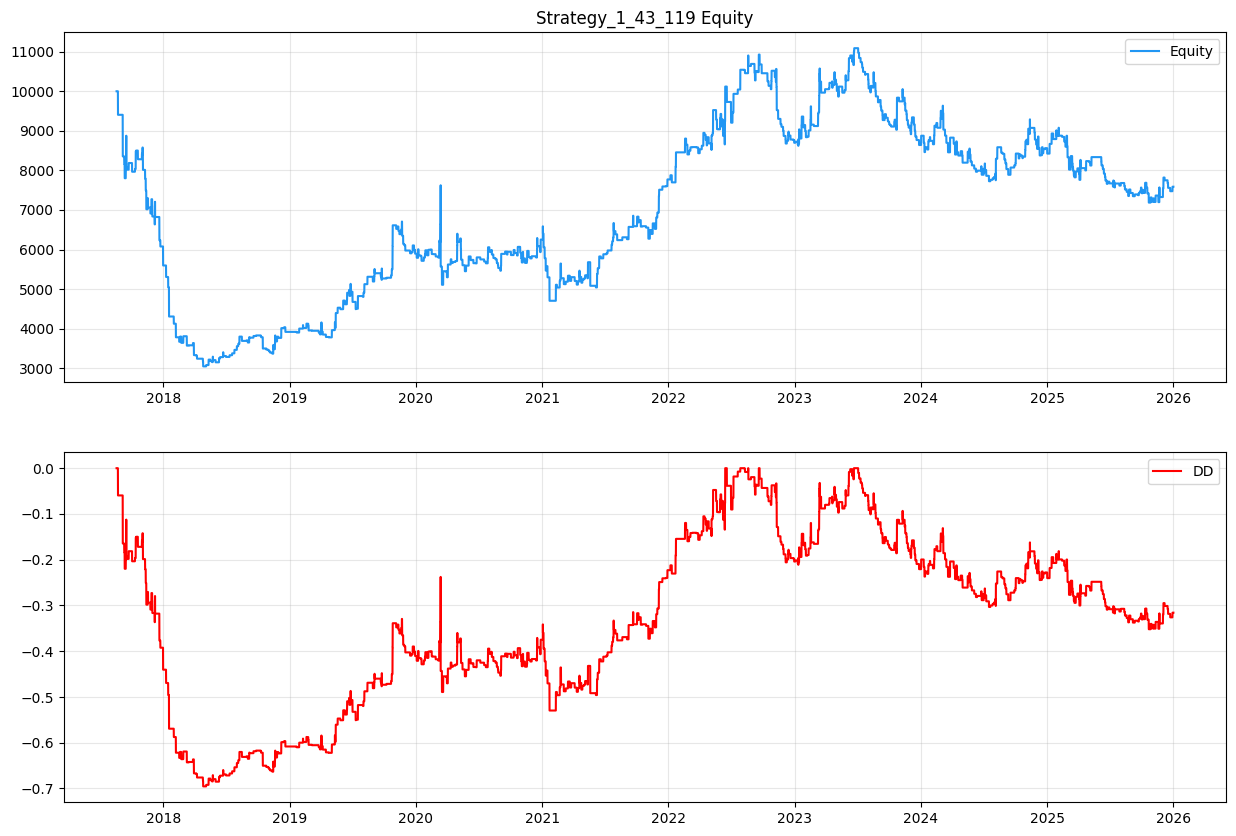

In [1]:
# ==============================================================================
# BƯỚC 1: CÀI ĐẶT THƯ VIỆN
# ==============================================================================
!pip install pandas_ta -q

import requests
import time
import pandas as pd
import pandas_ta as ta
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime

# ==============================================================================
# BƯỚC 2: CẤU HÌNH CHIẾN LƯỢC (Strategy_1_43_119 - Dual RSI Breakout)
# ==============================================================================
CONFIG = {
    'SYMBOL': 'BTCUSDT',
    'INTERVAL': '1h',
    'START_DATE': '01/01/2015',
    'END_DATE': '31/12/2025',
    'INITIAL_CAPITAL': 10000.0,

    # --- Indicators ---
    'KC_PERIOD': 20,
    'KC_MULT_SETUP': 1.5,    # Độ lệch chuẩn Keltner cho Setup

    'RSI1_PERIOD': 50,       # RSI dài hạn
    'RSI2_PERIOD': 30,       # RSI trung hạn

    'ATR_ENTRY_PERIOD': 14,  # ATR tính Buffer vào lệnh
    'ATR_SL_PERIOD': 20,     # ATR tính SL
    'ATR_PT_PERIOD': 30,     # ATR tính PT (Lưu ý: Code Java dùng ATR 30 cho PT)

    # --- Entry & Management ---
    'ENTRY_MULT': 2.4,       # Hệ số nhân với ATR(14)
    'SL_COEF': 2.0,          # 2.0 * ATR(20)
    'PT_COEF': 5.0,          # 5.0 * ATR(30)

    'USE_TRAILING': False,   # Chiến lược này không dùng Trailing Stop

    'ORDER_EXPIRATION': 4,   # Hủy lệnh sau 4 nến
    'TIME_EXIT_BARS': 18,    # Thoát sau 18 nến

    # Costs
    'FEE_RATE': 0.0004,
    'SLIPPAGE': 0.0002
}

# ==============================================================================
# BƯỚC 3: MODULE TẢI DỮ LIỆU
# ==============================================================================
def str_to_millis(date_str: str) -> int:
    dt = datetime.strptime(date_str, "%d/%m/%Y")
    return int(dt.timestamp() * 1000)

def fetch_binance_kline_df(symbol: str, interval: str, start_str: str, end_str: str) -> pd.DataFrame:
    base_url = "https://data-api.binance.vision/"
    url = base_url + "api/v3/klines"
    req_symbol = symbol.upper()

    print(f"📡 Checking connection to Binance...")
    try:
        test = requests.get(f"{base_url}/api/v3/time", timeout=5)
        if test.status_code == 451:
            print("⚠️ US IP detected. Switching to Binance.US...")
            base_url = "https://api.binance.us"
            if req_symbol == "BTCUSDT": req_symbol = "BTCUSD"
    except:
        print("⚠️ Connection failed. Retrying with Binance.US...")
        base_url = "https://api.binance.us"
        req_symbol = "BTCUSD"

    url = base_url + "/api/v3/klines"
    start_time = str_to_millis(start_str)

    if end_str == datetime.now().strftime("%d/%m/%Y"):
        end_time = int(time.time() * 1000)
    else:
        end_dt = datetime.strptime(end_str, "%d/%m/%Y").replace(hour=23, minute=59, second=59)
        end_time = int(end_dt.timestamp() * 1000)

    all_klines = []
    print(f"⏳ Downloading {req_symbol} ({interval}) from {base_url}...")

    while start_time < end_time:
        params = {"symbol": req_symbol, "interval": interval, "startTime": start_time, "endTime": end_time, "limit": 1000}
        try:
            r = requests.get(url, params=params, timeout=10)
            if r.status_code != 200: break
            data = r.json()
            if not data: break
            all_klines.extend(data)
            start_time = data[-1][0] + 1
            if len(all_klines) % 5000 == 0:
                print(f"   -> Downloaded: {len(all_klines)} candles")
            time.sleep(0.05)
        except: break

    if not all_klines: return pd.DataFrame()

    df = pd.DataFrame(all_klines, columns=["timestamp", "Open", "High", "Low", "Close", "Volume", "CT", "QAV", "NT", "TBBV", "TBQV", "I"])
    df = df[["timestamp", "Open", "High", "Low", "Close", "Volume"]]
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
    df.set_index("timestamp", inplace=True)
    df = df.astype(float)
    print(f"✅ Total: {len(df)} candles.")
    return df

# ==============================================================================
# BƯỚC 4: BACKTEST ENGINE (Logic Strategy_1_43_119)
# ==============================================================================
def run_strategy(df):
    print("⚙️ Calculating indicators & Running Strategy_1_43_119...")
    df = df.copy()
    c = CONFIG

    # --- A. INDICATORS ---
    # 1. Keltner Channels (20, 1.5) - Basis là SMA (Mặc định SQ)
    kc_basis = ta.sma(df['Close'], length=c['KC_PERIOD'])
    kc_range = ta.atr(df['High'], df['Low'], df['Close'], length=c['KC_PERIOD'])
    df['KC_Upper'] = kc_basis + (c['KC_MULT_SETUP'] * kc_range)
    df['KC_Lower'] = kc_basis - (c['KC_MULT_SETUP'] * kc_range)

    # 2. RSI Indicators
    # RSI 1: Period 50, Weighted Close (High+Low+2*Close)/4
    # Pandas TA hlc3 tương đương Weighted Close nếu không có Volume, hoặc ta tự tính
    weighted_close = (df['High'] + df['Low'] + 2 * df['Close']) / 4
    df['RSI_50'] = ta.rsi(weighted_close, length=c['RSI1_PERIOD'])

    # RSI 2: Period 30, Close
    df['RSI_30'] = ta.rsi(df['Close'], length=c['RSI2_PERIOD'])

    # 3. ATRs
    df['ATR_Entry'] = ta.atr(df['High'], df['Low'], df['Close'], length=c['ATR_ENTRY_PERIOD'])
    df['ATR_SL']    = ta.atr(df['High'], df['Low'], df['Close'], length=c['ATR_SL_PERIOD'])
    df['ATR_PT']    = ta.atr(df['High'], df['Low'], df['Close'], length=c['ATR_PT_PERIOD'])

    df.dropna(inplace=True)

    # --- B. INITIALIZATION ---
    capital = c['INITIAL_CAPITAL']
    position = 0; entry_price = 0.0; entry_idx = 0
    sl_price = 0.0; tp_price = 0.0
    pending_orders = []; trades = []
    equity_curve = [c['INITIAL_CAPITAL']] * len(df)

    # Numpy Arrays
    opens = df['Open'].values; highs = df['High'].values; lows = df['Low'].values; closes = df['Close'].values
    times = df.index

    # Indicators Array
    kc_upper = df['KC_Upper'].values; kc_lower = df['KC_Lower'].values
    rsi_50 = df['RSI_50'].values; rsi_30 = df['RSI_30'].values
    atr_entry = df['ATR_Entry'].values
    atr_sl = df['ATR_SL'].values; atr_pt = df['ATR_PT'].values

    # --- C. MAIN LOOP ---
    for i in range(1, len(df)):

        # 1. QUẢN LÝ LỆNH ĐANG CHẠY (EXIT)
        if position != 0:
            exit_signal = False; exit_reason = ""; raw_exit_price = closes[i]

            if position == 1:
                if lows[i] <= sl_price:
                    exit_signal = True; exit_reason = "SL Hit"; raw_exit_price = sl_price
                elif highs[i] >= tp_price:
                    exit_signal = True; exit_reason = "PT Hit"; raw_exit_price = tp_price
                elif (i - entry_idx) >= c['TIME_EXIT_BARS']:
                    exit_signal = True; exit_reason = "Time Exit"; raw_exit_price = closes[i]

            elif position == -1:
                if highs[i] >= sl_price:
                    exit_signal = True; exit_reason = "SL Hit"; raw_exit_price = sl_price
                elif lows[i] <= tp_price:
                    exit_signal = True; exit_reason = "PT Hit"; raw_exit_price = tp_price
                elif (i - entry_idx) >= c['TIME_EXIT_BARS']:
                    exit_signal = True; exit_reason = "Time Exit"; raw_exit_price = closes[i]

            if exit_signal:
                # Tính PnL
                if position == 1:
                    real_exit = min(opens[i], raw_exit_price) if "SL" in exit_reason else raw_exit_price
                    real_exit *= (1 - c['SLIPPAGE'])
                    pnl = (real_exit - entry_price) / entry_price
                else:
                    real_exit = max(opens[i], raw_exit_price) if "SL" in exit_reason else raw_exit_price
                    real_exit *= (1 + c['SLIPPAGE'])
                    pnl = (entry_price - real_exit) / entry_price

                net_pnl = pnl - (c['FEE_RATE'] * 2)
                capital += (capital * net_pnl)

                trades.append({'Date': times[i], 'Type': 'Long' if position == 1 else 'Short', 'Reason': exit_reason, 'PnL': capital * net_pnl, 'Equity': capital})
                position = 0; pending_orders = []

            # (Không có Trailing Stop)

        # 2. XỬ LÝ LỆNH CHỜ (ENTRY)
        if position == 0:
            # Lọc lệnh hết hạn (4 nến)
            pending_orders = [o for o in pending_orders if (i - o['created_idx']) < c['ORDER_EXPIRATION']]

            triggered = None
            for order in pending_orders:
                if order['type'] == 'buy' and highs[i] >= order['price']:
                    triggered = order; exec_price = max(opens[i], order['price']) if opens[i] > order['price'] else order['price']
                    break
                elif order['type'] == 'sell' and lows[i] <= order['price']:
                    triggered = order; exec_price = min(opens[i], order['price']) if opens[i] < order['price'] else order['price']
                    break

            if triggered:
                entry_idx = i
                if triggered['type'] == 'buy':
                    position = 1
                    entry_price = exec_price * (1 + c['SLIPPAGE'])
                    sl_price = exec_price - (c['SL_COEF'] * atr_sl[i])
                    tp_price = exec_price + (c['PT_COEF'] * atr_pt[i])
                else:
                    position = -1
                    entry_price = exec_price * (1 - c['SLIPPAGE'])
                    sl_price = exec_price + (c['SL_COEF'] * atr_sl[i])
                    tp_price = exec_price - (c['PT_COEF'] * atr_pt[i])

                pending_orders = []

        # 3. TẠO TÍN HIỆU MỚI (Logic Strategy_1_43_119)
        if position == 0:
            # Shift 1 là nến trước đó, Shift 2 là nến trước nữa
            # RSI Rising: rsi[i-2] < rsi[i-1] (Giá trị RSI 1 nến trước > Giá trị RSI 2 nến trước)
            # RSI Falling: rsi[i-2] > rsi[i-1]

            # Lưu ý logic RSI trong Java:
            # RSI(1+1) < RSI(1) -> RSI(shift 2) < RSI(shift 1) -> RSI đang TĂNG

            rsi50_rising = rsi_50[i-2] < rsi_50[i-1]
            rsi50_falling = rsi_50[i-2] > rsi_50[i-1]

            # RSI(3+1) < RSI(3) -> RSI(shift 4) < RSI(shift 3) -> RSI đang TĂNG
            rsi30_rising = rsi_30[i-4] < rsi_30[i-3]
            rsi30_falling = rsi_30[i-4] > rsi_30[i-3]

            # Logic KC: Open > KC Upper (Shift 1 - vì backtest vector i là nến hiện tại đang chạy)
            # Nhưng trong Java "sqGetValue(Open, 0)" là giá Open của nến hiện tại (chưa đóng)
            # Trong backtest vector, opens[i] chính là giá Open của nến hiện tại.

            # Setup Long: Open > KC Upper (1.5) & RSI 50 Rising & RSI 30 Rising
            # Ta dùng kc_upper[i-1] vì KC được tính dựa trên giá đóng cửa nến trước
            setup_long = (opens[i] > kc_upper[i-1]) and rsi50_rising and rsi30_rising

            # Setup Short: Open < KC Lower (1.5) & RSI 50 Falling & RSI 30 Falling
            setup_short = (opens[i] < kc_lower[i-1]) and rsi50_falling and rsi30_falling

            # Entry Calculation: Current Ask/Bid +/- 2.4 ATR (shift 2)
            # Trong backtest dùng giá Close[i-1] làm tham chiếu gần đúng cho giá hiện tại để đặt lệnh chờ
            buffer = c['ENTRY_MULT'] * atr_entry[i-2] # ATR shift 2

            if setup_long:
                # Buy Stop: Giá hiện tại + buffer
                pending_orders.append({'type': 'buy', 'price': opens[i] + buffer, 'created_idx': i})

            if setup_short and not setup_long:
                pending_orders.append({'type': 'sell', 'price': opens[i] - buffer, 'created_idx': i})

        equity_curve[i] = capital

    return pd.Series(equity_curve, index=df.index), pd.DataFrame(trades)

# ==============================================================================
# BƯỚC 5: RUN & REPORT
# ==============================================================================
if __name__ == "__main__":
    df = fetch_binance_kline_df(CONFIG['SYMBOL'], CONFIG['INTERVAL'], CONFIG['START_DATE'], CONFIG['END_DATE'])

    if not df.empty:
        equity, trades_df = run_strategy(df)

        if not trades_df.empty:
            final_equity = equity.iloc[-1]
            total_return = (final_equity - CONFIG['INITIAL_CAPITAL']) / CONFIG['INITIAL_CAPITAL']

            rolling_max = equity.cummax()
            dd = (equity - rolling_max) / rolling_max
            max_dd = dd.min()

            wins = trades_df[trades_df['PnL'] > 0]
            losses = trades_df[trades_df['PnL'] <= 0]
            winrate = len(wins) / len(trades_df) if len(trades_df) > 0 else 0

            gross_profit = wins['PnL'].sum(); gross_loss = abs(losses['PnL'].sum())
            profit_factor = gross_profit / gross_loss if gross_loss != 0 else 0

            days = (equity.index[-1] - equity.index[0]).days
            cagr = ((final_equity / CONFIG['INITIAL_CAPITAL']) ** (365.0 / days)) - 1 if days > 0 else 0

            returns = equity.pct_change().dropna()
            sharpe_ratio = (returns.mean() / returns.std()) * np.sqrt(365 * 24) if returns.std() != 0 else 0

            print(f"\n{'='*30}")
            print(f"📊 BACKTEST: Strategy_1_43_119 ({CONFIG['SYMBOL']})")
            print(f"{'='*30}")
            print(f"{'Final Equity:':>15} {final_equity:,.2f}")
            print(f"{'Total Return:':>15} {total_return:.2%}")
            print(f"{'CAGR (approx):':>15} {cagr:.2%}")
            print(f"{'Max Drawdown:':>15} {max_dd:.2%}")
            print(f"{'Sharpe Ratio:':>15} {sharpe_ratio:.2f}")
            print(f"{'Trades:':>15} {len(trades_df)}")
            print(f"{'Winrate:':>15} {winrate:.2%}")
            print(f"{'Profit Factor:':>15} {profit_factor:.2f}")
            print(f"{'='*30}")

            plt.figure(figsize=(15, 10))
            plt.subplot(2, 1, 1)
            plt.plot(equity, label='Equity', color='#2196F3'); plt.grid(True, alpha=0.3); plt.legend()
            plt.title('Strategy_1_43_119 Equity')
            plt.subplot(2, 1, 2)
            plt.plot(dd, label='DD', color='red'); plt.grid(True, alpha=0.3); plt.legend()
            plt.show()
        else:
            print("⚠️ No trades executed.")
    else:
        print("❌ No data.")